/var/folders/m9/_g3wndrn04d80ys2382r700r0000gn/T/ipykernel_81839/2905454065.py:60: DeprecationWarning: `salib.sample.saltelli` will be removed in SALib 1.5. Please use `salib.sample.sobol`
  param_values = saltelli.sample(problem, 1000)
/Users/doughnut/opt/anaconda3/lib/python3.9/site-packages/SALib/sample/saltelli.py:109: UserWarning: 
        Convergence properties of the Sobol' sequence is only valid if
        `N` (1000) is equal to `2^n`.
        
  warnings.warn(msg)


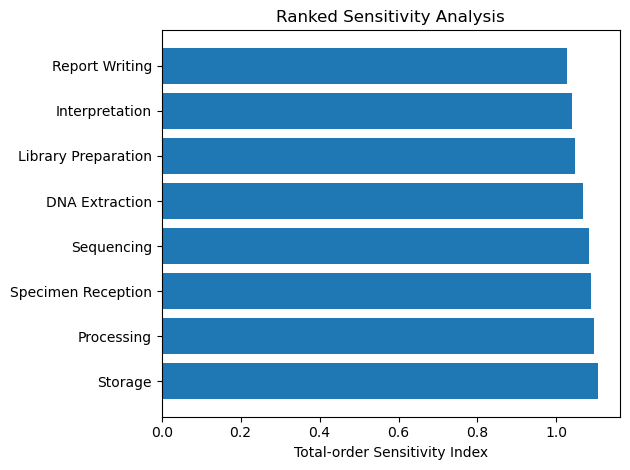

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gamma
from SALib.sample import saltelli
from SALib.analyze import sobol

# Create DataFrame
data = {
    'Category': ['Equipment', 'Equipment', 'Equipment', 'Equipment', 'Equipment', 
                 'Consumables', 'Consumables', 'Labour', 'Labour', 'Labour', 'Labour', 
                 'Labour', 'Labour', 'Overheads', 'Overheads', 'Overheads', 'Overheads', 
                 'Overheads', 'Overheads', 'Overheads', 'Overheads'],
    'Stage': ['DNA Extraction', 'Library Preparation', 'Sequencing', 'Storage', 
              'Interpretation', 'DNA Extraction', 'Library Preparation', 'Specimen Reception', 
              'DNA Extraction', 'Library Preparation', 'Sequencing', 'Processing', 'Report Writing', 
              'Specimen Reception', 'DNA Extraction', 'Library Preparation', 'Sequencing', 
              'Processing', 'Storage', 'Interpretation', 'Report Writing'],
    'LL': [0.056264887, 46.28672142, 28.44780984, 0.124583333, 9.300146939, 
           0.086868, 0.08075, 8.053405942, 3.701139752, 3.090046979, 296.64451, 
           1.427908855, 8.240125278, 1.610681188, 0.768854528, 9.891503681, 65.01846397, 
           0.285581771, 0.024916667, 1.860029388, 1.648025056],
    'UL': [0.050880687, 76.73851184, 47.16347421, 0.3375, 15.41866466, 
           0.109728, 0.102, 11.15748296, 5.127694296, 5.802887237, 557.0771748, 
           4.450935223, 15.47436597, 2.231496592, 1.057660597, 16.52867981, 120.8481298, 
           0.890187045, 0.0675, 3.083732932, 3.094873193]
}
df = pd.DataFrame(data)

# Ensure lower limit < upper limit
df['LL'], df['UL'] = np.where(df['LL'] > df['UL'], (df['UL'], df['LL']), (df['LL'], df['UL']))

# Estimate parameters of gamma distribution
a_values, scale_values = [], []
for _, row in df.iterrows():
    mean = (row['LL'] + row['UL']) / 2
    variance = ((row['UL'] - row['LL']) / 2)**2
    alpha = mean**2 / variance
    scale = variance / mean
    
    a_values.append(alpha)
    scale_values.append(scale)

df['alpha'], df['scale'] = a_values, scale_values

# Define a model function using gamma distributions
def model(x):
    outputs = np.zeros(x.shape[0])
    for i, (_, row) in enumerate(df.iterrows()):
        outputs += gamma.rvs(row['alpha'], scale=row['scale'], size=x.shape[0])
    return outputs

# Use SAlib for sensitivity analysis
problem = {
    'num_vars': len(df),
    'names': df['Stage'].tolist(),
    'bounds': df[['LL', 'UL']].values.tolist()
}

param_values = saltelli.sample(problem, 1000)

Y = model(param_values)

Si = sobol.analyze(problem, Y)

# Rank stages by sensitivity in descending order
ranked_indices = np.argsort(Si['ST'])[::-1]
ranked_stages = [df['Stage'].iloc[i] for i in ranked_indices]

# Visualize the results vertically
plt.barh(ranked_stages, Si['ST'][ranked_indices], align='center')
plt.xlabel('Total-order Sensitivity Index')
plt.title('Ranked Sensitivity Analysis')
plt.tight_layout()
plt.show()

#convert x-axis labels to actual value


/var/folders/m9/_g3wndrn04d80ys2382r700r0000gn/T/ipykernel_81839/414454896.py:18: DeprecationWarning: `salib.sample.saltelli` will be removed in SALib 1.5. Please use `salib.sample.sobol`
  param_values_sobol = saltelli.sample(problem, 1000)
/Users/doughnut/opt/anaconda3/lib/python3.9/site-packages/SALib/sample/saltelli.py:109: UserWarning: 
        Convergence properties of the Sobol' sequence is only valid if
        `N` (1000) is equal to `2^n`.
        
  warnings.warn(msg)


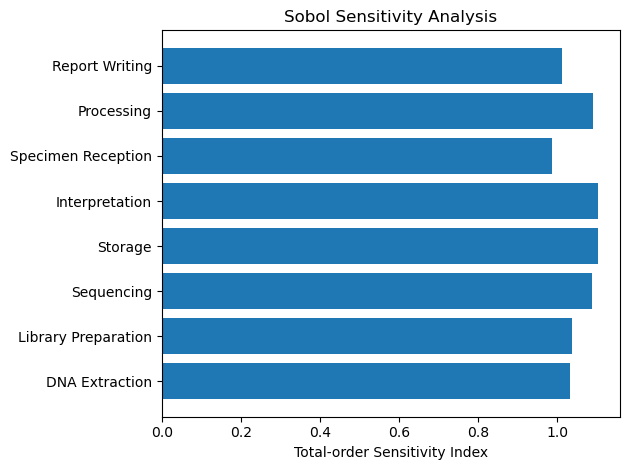

ValueError: shape mismatch: objects cannot be broadcast to a single shape.  Mismatch is between arg 2 with shape (8,) and arg 3 with shape (21,).

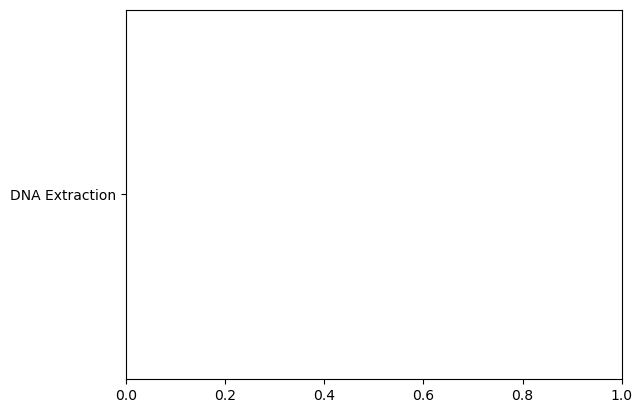

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gamma
from SALib.sample import saltelli, morris as morris_sample, latin, fast_sampler
from SALib.analyze import sobol, morris as morris_analyze, delta, fast

# ... [Your data processing and model definition code here] ...

# Problem definition for SALib
problem = {
    'num_vars': len(df),
    'names': df['Stage'].tolist(),
    'bounds': df[['LL', 'UL']].values.tolist()
}

# Sobol Sensitivity Analysis
param_values_sobol = saltelli.sample(problem, 1000)
Y_sobol = model(param_values_sobol)
Si_sobol = sobol.analyze(problem, Y_sobol)
plt.figure()
plt.barh(df['Stage'], Si_sobol['ST'])
plt.xlabel('Total-order Sensitivity Index')
plt.title('Sobol Sensitivity Analysis')
plt.tight_layout()
plt.show()

# Morris Method
param_values_morris = morris_sample.sample(problem, 1000)
Y_morris = model(param_values_morris)
mi_morris = morris_analyze.analyze(problem, param_values_morris, Y_morris)
plt.figure()
plt.barh(df['Stage'], mi_morris['mu_star'])
plt.xlabel('Mean Absolute Elementary Effect')
plt.title('Morris Sensitivity Analysis')
plt.tight_layout()
plt.show()

# Delta Moment-Independent Measure
param_values_delta = latin.sample(problem, 1000)
Y_delta = model(param_values_delta)
Di_delta = delta.analyze(problem, Y_delta, param_values_delta, num_resamples=10, conf_level=0.95)
plt.figure()
plt.barh(df['Stage'], Di_delta['delta'])
plt.xlabel('Delta Measure')
plt.title('Delta Moment-Independent Measure Sensitivity Analysis')
plt.tight_layout()
plt.show()

# FAST
param_values_fast = fast_sampler.sample(problem, 1000)
Y_fast = model(param_values_fast)
Fi_fast = fast.analyze(problem, Y_fast)
plt.figure()
plt.barh(df['Stage'], Fi_fast['ST'])
plt.xlabel('Total-order Sensitivity Index')
plt.title('FAST Sensitivity Analysis')
plt.tight_layout()
plt.show()


/var/folders/m9/_g3wndrn04d80ys2382r700r0000gn/T/ipykernel_81839/759976256.py:18: DeprecationWarning: `salib.sample.saltelli` will be removed in SALib 1.5. Please use `salib.sample.sobol`
  param_values_sobol = saltelli.sample(problem, 1000)
/Users/doughnut/opt/anaconda3/lib/python3.9/site-packages/SALib/sample/saltelli.py:109: UserWarning: 
        Convergence properties of the Sobol' sequence is only valid if
        `N` (1000) is equal to `2^n`.
        
  warnings.warn(msg)


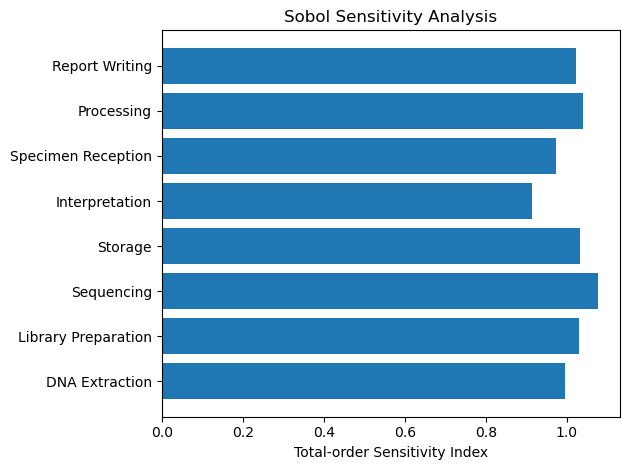

TypeError: sample() got an unexpected keyword argument 'grid_jump'

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gamma
from SALib.sample import saltelli, morris as morris_sample, latin, fast_sampler
from SALib.analyze import sobol, morris as morris_analyze, delta, fast

# ... [Your data processing and model definition code here] ...

# Problem definition for SALib
problem = {
    'num_vars': len(df),
    'names': df['Stage'].tolist(),
    'bounds': df[['LL', 'UL']].values.tolist()
}

# Sobol Sensitivity Analysis
param_values_sobol = saltelli.sample(problem, 1000)
Y_sobol = model(param_values_sobol)
Si_sobol = sobol.analyze(problem, Y_sobol)
plt.figure()
plt.barh(df['Stage'], Si_sobol['ST'])
plt.xlabel('Total-order Sensitivity Index')
plt.title('Sobol Sensitivity Analysis')
plt.tight_layout()
plt.show()

# Morris Method
param_values_morris = morris_sample.sample(problem, 1000, num_levels=4, grid_jump=2)
Y_morris = model(param_values_morris)
mi_morris = morris_analyze.analyze(problem, param_values_morris, Y_morris, conf_level=0.95, print_to_console=True, num_levels=4, grid_jump=2)

# Average the sensitivity values for each stage
mu_star_avg = [np.mean(mi_morris['mu_star'][i::len(df['Stage'])]) for i in range(len(df['Stage']))]

# Visualization
plt.figure()
plt.barh(df['Stage'], mu_star_avg)
plt.xlabel('Mean Absolute Elementary Effect')
plt.title('Morris Sensitivity Analysis')
plt.tight_layout()
plt.show()

# Delta Moment-Independent Measure
param_values_delta = latin.sample(problem, 1000)
Y_delta = model(param_values_delta)
Di_delta = delta.analyze(problem, Y_delta, param_values_delta, num_resamples=10, conf_level=0.95)
plt.figure()
plt.barh(df['Stage'], Di_delta['delta'])
plt.xlabel('Delta Measure')
plt.title('Delta Moment-Independent Measure Sensitivity Analysis')
plt.tight_layout()
plt.show()

# FAST
param_values_fast = fast_sampler.sample(problem, 1000)
Y_fast = model(param_values_fast)
Fi_fast = fast.analyze(problem, Y_fast)
plt.figure()
plt.barh(df['Stage'], Fi_fast['ST'])
plt.xlabel('Total-order Sensitivity Index')
plt.title('FAST Sensitivity Analysis')
plt.tight_layout()
plt.show()
